# 4. NER and entity sentiment

spaCy `en_core_web_lg` was already run on `original_text`. This notebook does **not** rerun NER.

Guideline rule: entities shorter than **3 characters** are excluded from the graded cleaned table. `CW` and `VN` are therefore gone from the cleaned outputs. `entities_extracted.csv` (193 MB) remains the unfiltered extraction record and is excluded from the submission package.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

def find_root() -> Path:
    start = Path.cwd().resolve()
    for p in [start, *start.parents]:
        if (p / "outputs").is_dir() and (p / "src").is_dir():
            return p
    raise FileNotFoundError(
        "Cannot find the project root (need outputs/ and src/). "
        "Open this notebook from the repo, from notebooks/, or from a guideline folder."
    )

ROOT = find_root()
OUT = ROOT / "outputs"
print("ROOT =", ROOT)
print("This notebook reads shipped CSVs and PNGs only.")
print("It does not open IFB.db, does not open any analysis database,")
print("and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.")


ROOT = C:\Users\yosef\OneDrive\שולחן העבודה\IFB-project
This notebook reads shipped CSVs and PNGs only.
It does not open IFB.db, does not open any analysis database,
and does not rerun sentiment, emotion, BERTopic, NER, network, or bot models.


entities_cleaned 255139 short_rows 0
dropped_short_rows 1352
ampersand_rows 0
[embedded figure] person_entities_sentiment.png (108,766 bytes)
[embedded figure] country_entities_sentiment.png (106,150 bytes)
DONE NER verification


ner_entity_analysis.ipynb:2:1: DtypeWarning: Columns (0: representative_tweet_ids, 1: representative_texts) have mixed types. Specify dtype option on import or set low_memory=False.


,canonical_entity,entity,entity_type,normalized_category,entity_label_mode,n_mentions,Count,n_posts,n_users,n_keyword,n_timeline,n_positive,n_neutral,n_negative,positive,neutral,negative,pct_positive,pct_neutral,pct_negative,avg_sentiment_positive,avg_sentiment_neutral,avg_sentiment_negative,date_min,date_max,singleton_flag,variants,representative_tweet_ids,representative_texts,count_note
0,Twitter,Twitter,organization,organization,ORG,9703,9001,9001,4581,6255,2746,2267,5520,1214,2267,5520,1214,25.19,61.33,13.49,0.2835,0.5752,0.1412,2007-07-30T01:49:34,2023-11-25T16:04:25,0,"Twitter (7887), twitter (1679), TWITTER (137)",keyword_tweets:1080135741966114818|keyword_tweets:1080589776426815488|keyword_tweets:1080590034917605376|keyword_tweets:1080590197006442496,"@SinghLions @SeaWorldSD @HardeepSPuri @parrysingh @TanDhesi @inflowsummits @SikhProf @SikhFeminist @mssirsa @sikh_coalition Thank you for following me on Twitter. Happy New Year to your family and the newest member of yo || @RaisingIT thank you so much for following me on Twitter and happy to follow you back in return. Hope your New year's day was a blast! Have a great successful start up! || @whynotvoid thanks for following me on Twitter and happy to follow you back in return. Hope your New year's day was a blast! Have a great successful start up! You got some amazing work || @stayblesst thank you so much for following me on Twitter and happy to follow you back in return. Hope your New year's day was a blast! Have a great successful start up, good man!","sentiment counts are unique posts, not mention copies; unweighted analysis-file mix"
1,United States,United States,country,country,GPE,6142,5809,5809,2655,2352,3457,752,3781,1276,752,3781,1276,12.95,65.09,21.97,0.1582,0.6199,0.2220,2009-04-23T13:29:23,2023-11-24T18:05:32,0,"US (3780), America (1410), USA (563), United States (113), Us (108), us (77), america (44), AMERICA (26)",keyword_tweets:1082042167680532480|keyword_tweets:1083043742653677569|keyword_tweets:1089387060203585536|keyword_tweets:1091820066465710080,"thanks 4 follow #PrabhuStudio John Hall From #Missouri, USA https://t.co/8H9bxhjd6I Co-founder Calendar influenceandco, Author https://t.co/kooAllJ6mQ, Book me to speak at https://t.co/kbdTiBcUuj, most important father/h || followme - Despite promises to stop, US cell carriers are still selling your real-time phone location data https://t.co/xKQOzkNr8x - followforfollow https://t.co/N7C0cZB5Ua || @lhettinger Thx4 return follow. Gave your Only in America tweet a like&amp;RT. I would love U2return favor &amp; RT 1 of my tweets. #Amwriting novel Cult. See my pinned tweet 4 more on that. #MMT #Atheist #Science #Secul || follow me - Follow live: USA takes on Costa Rica in an international friendly: The USMNT, coming off a victory over Panama, look to make it two in a row in the Gregg Berhalter era.- followforfollow https://t.co/gcDcWEQiG","sentiment counts are unique posts, not mention copies; unweighted analysis-file mix"
2,Donald Trump,Donald Trump,person,person,ORG,4532,4212,4212,1424,1473,2739,224,2478,1510,224,2478,1510,5.32,58.83,35.85,0.0794,0.5553,0.3653,2015-10-29T02:13:29,2023-11-26T04:04:49,0,"Trump (3766), Donald Trump (560), TRUMP (62), trump (41), tRump (40), Donald J. Trump (18), Donald J Trump (17), donald trump (13)",keyword_tweets:1082063683923132417|keyword_tweets:1084108134426255362|keyword_tweets:1084548696874741760|keyword_tweets:1088137028816928768,"How true this statement us. God is our only hope but God have us Trump for a reason. Together they will lead but we must follow! || Why do so many ppl I follow, follow him? #ArtemKlyushin is a Russian billionaire who serves as councillor to the Kremlin. Back in 2017, Klyushin took 2 Twitter 2 boast that Trump would never have been elected Prez if not || More bullshit from Trump this is bullshit these people want their damn money and they will not work for free screw you Donald Trump &amp; your fucking people that follow you you're a bunch of assh

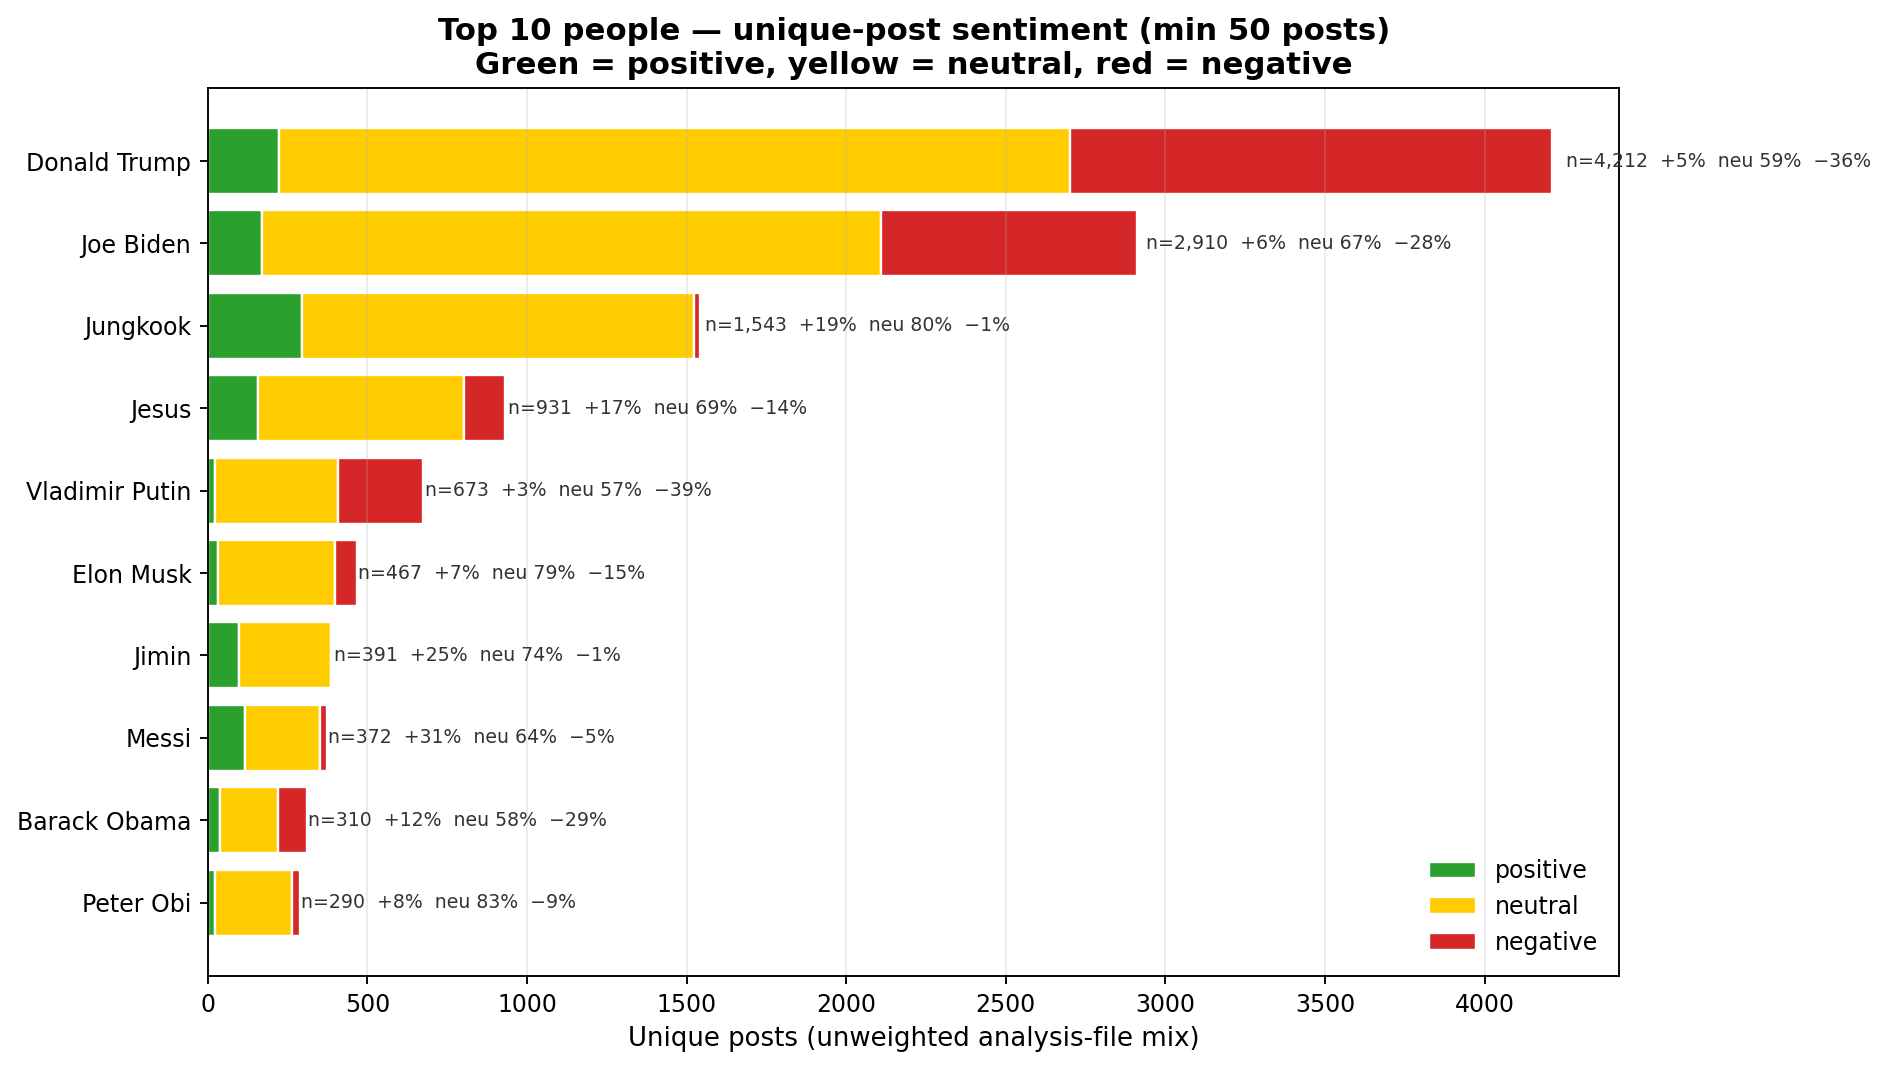

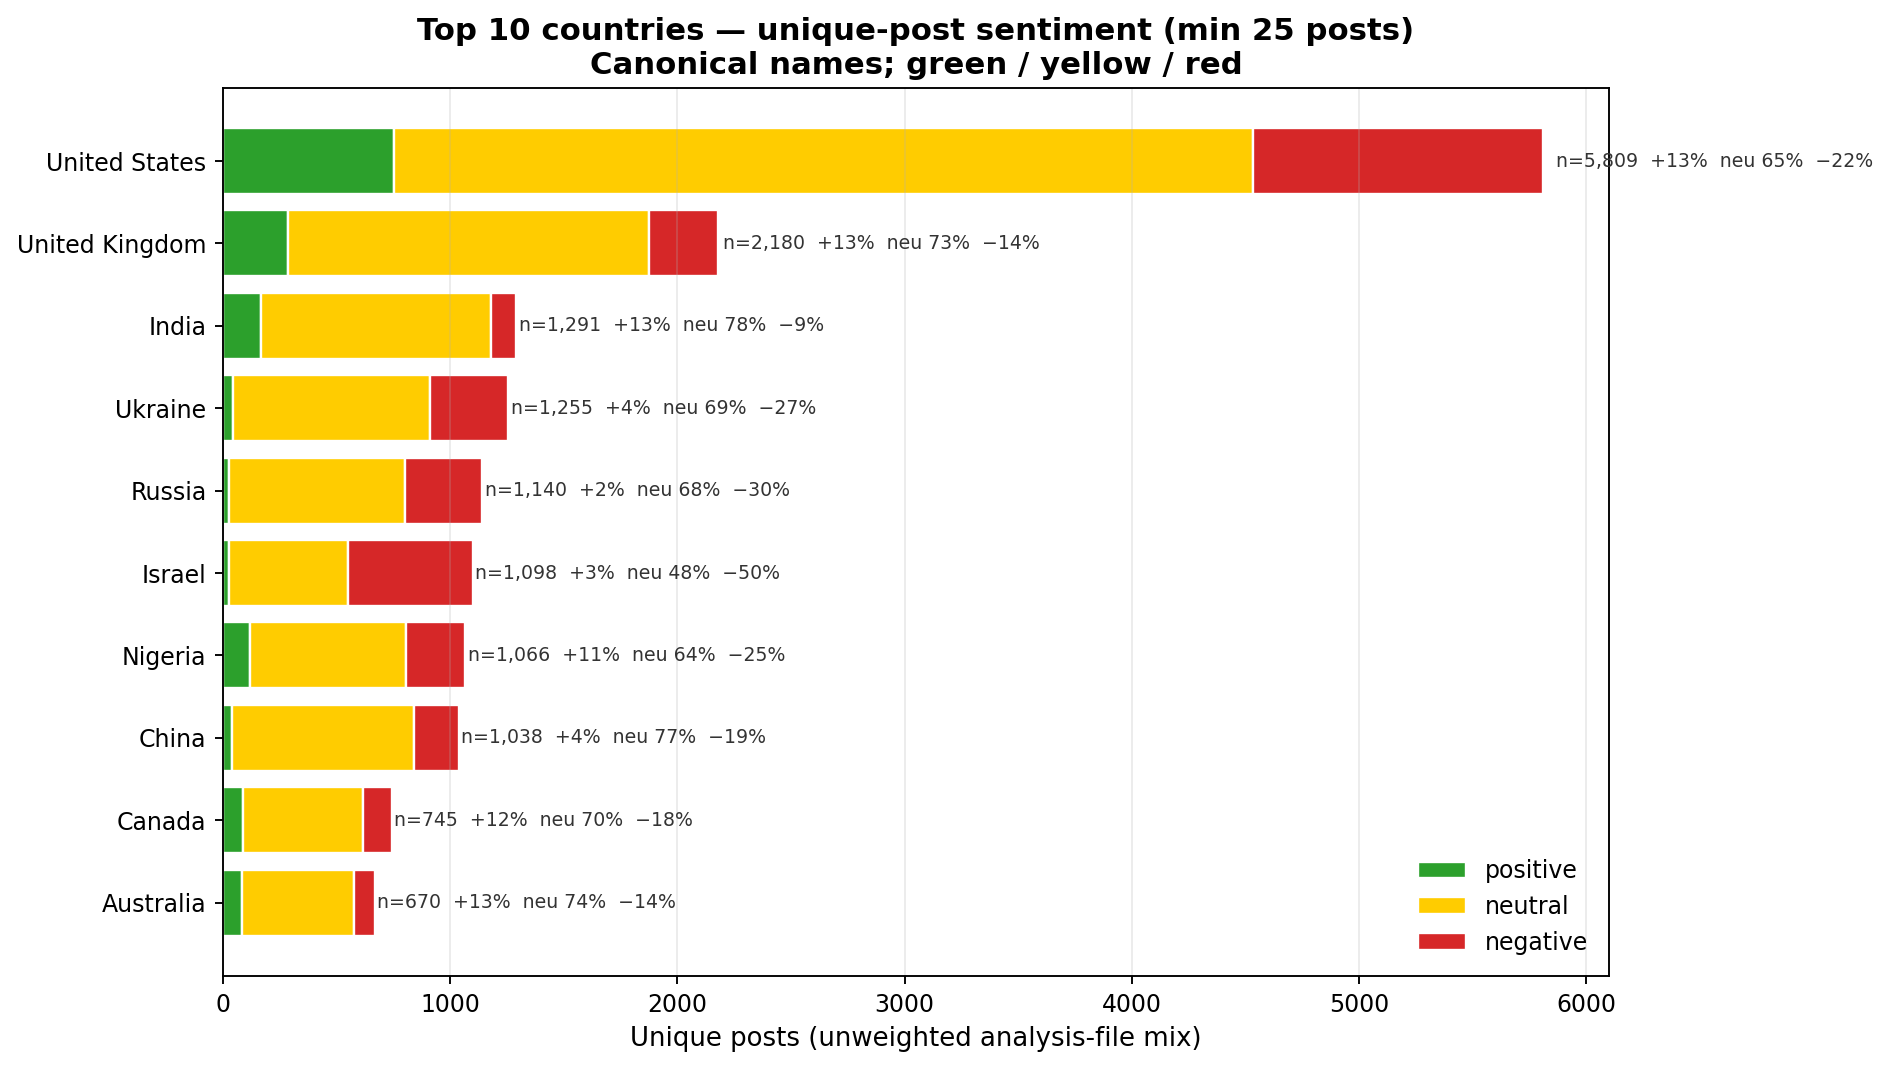

In [2]:
cleaned = pd.read_csv(OUT / "entities_cleaned.csv", encoding="utf-8-sig")
name_col = "canonical_entity" if "canonical_entity" in cleaned.columns else "entity"
short = cleaned[cleaned[name_col].astype(str).str.len() < 3]
print("entities_cleaned", len(cleaned), "short_rows", len(short))
assert len(short) == 0
dropped = OUT / "entities_dropped_short.csv"
if dropped.exists():
    d = pd.read_csv(dropped, encoding="utf-8-sig")
    print("dropped_short_rows", len(d))
amp = cleaned[cleaned[name_col].astype(str).str.strip() == "&"]
print("ampersand_rows", len(amp))
assert len(amp) == 0
display(cleaned.head(8))
display(Image(filename=str(OUT / "person_entities_sentiment.png")))
display(Image(filename=str(OUT / "country_entities_sentiment.png")))
print("DONE NER verification")
